In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier , plot_tree, DecisionTreeRegressor
from sklearn.metrics import accuracy_score, r2_score
from sklearn.compose import ColumnTransformer , make_column_selector,make_column_transformer 
from sklearn.preprocessing import OneHotEncoder 
from sklearn.pipeline import Pipeline
from tqdm import tqdm

from sklearn.model_selection import train_test_split

import os 
os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')

In [2]:
housing = pd.read_csv('Housing.csv')
housing

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000.0,6360,2,1,1,yes,no,no,no,no,0,no
...,...,...,...,...,...,...,...,...,...,...,...,...
541,91500.0,4800,3,2,4,yes,yes,no,no,yes,0,no
542,94000.0,6000,3,2,4,yes,no,no,no,yes,0,no
543,103000.0,6000,3,2,4,yes,yes,no,no,yes,1,no
544,105000.0,6000,3,2,2,yes,yes,no,no,yes,1,no


In [6]:
X , y = housing.drop('price' , axis  = 1) , housing['price']

X_train , X_test , y_train, y_test = train_test_split(X,y,test_size=0.3 ,  random_state=26)

In [40]:
ohe = OneHotEncoder(sparse_output=False , drop='first').set_output(transform='pandas')
ct = make_column_transformer(
    ( ohe, make_column_selector(dtype_include='object')),
    ( 'passthrough', make_column_selector(dtype_include=['int64', 'float64'])),
    verbose_feature_names_out=False
).set_output(transform = 'pandas')


In [12]:
mu = y_train.mean()
np.mean((y_train-mu) **2)

np.float64(713741358.9815862)

In [44]:

X_trn_ohe , x_tst_ohe = ct.fit_transform(X_train), ct.transform(X_test)


In [53]:


depths = [None, 2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf=[1,5,10,20,50]

scores = []

for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26 , max_depth=d , min_samples_split=s, min_samples_leaf=f)

            dtr.fit(X_trn_ohe, y_train)
            y_pred = dtr.predict(x_tst_ohe) 
              
            scores.append([d,s,f,r2_score(y_test, y_pred)])

df_scores  = pd.DataFrame(scores , columns=['Depth','Splits','Leaf','Score'])
df_scores.sort_values('Score' , ascending=False)

100%|██████████| 7/7 [00:00<00:00,  7.84it/s]


,Depth,Splits,Leaf,Score
23,NaN,50,20,0.530931
173,7.0,50,20,0.530931
148,6.0,50,20,0.530931
123,5.0,50,20,0.530931
171,7.0,50,5,0.528372
...,...,...,...,...
10,NaN,10,1,0.353734
155,7.0,5,1,0.329882
5,NaN,5,1,0.290221
0,NaN,2,1,0.286557


Text(0.5, 1.0, 'Feature importances plot')

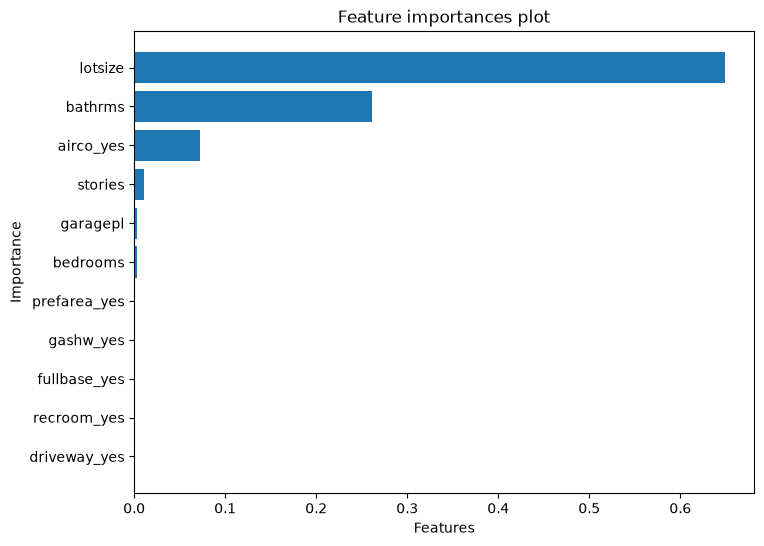

In [54]:
 

bestTree = DecisionTreeRegressor(random_state=26,min_samples_split=50, min_samples_leaf=20,max_depth=None)
 
bestTree.fit(X_trn_ohe , y_train)

df_imp = pd.DataFrame({'features':list(X_trn_ohe.columns),
                          'importance': bestTree.feature_importances_})

df_imp.sort_values('importance',inplace=True)
plt.figure(figsize=(8,6))
plt.barh(df_imp['features'], df_imp['importance'])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Feature importances plot')

# DescisionTreeRegressor  op: Strength

In [55]:
os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\Concrete_Strength')

concrete_data = pd.read_csv('Concrete_Data.csv')
concrete_data

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [57]:
X , y = concrete_data.drop('Strength' , axis = 1) , concrete_data['Strength']
X_train , X_test , y_train, y_test = train_test_split(X,y,test_size=0.3 ,  random_state=26)

In [58]:


depths = [None ,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []

for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26 , max_depth=d , min_samples_split=s, min_samples_leaf=f)

            dtr.fit(X_train, y_train)
            y_pred = dtr.predict(X_test) 
              
            scores.append([d,s,f,r2_score(y_test, y_pred)])

df_scores  = pd.DataFrame(scores , columns=['Depth','Splits','Leaf','Score'])
df_scores.sort_values('Score' , ascending=False)

100%|██████████| 7/7 [00:01<00:00,  5.55it/s]


,Depth,Splits,Leaf,Score
0,NaN,2.00,1.0,0.850026
12,NaN,0.01,1.0,0.833292
228,7.0,0.01,1.0,0.797718
180,6.0,2.00,1.0,0.795930
222,7.0,0.05,1.0,0.794303
...,...,...,...,...
227,7.0,0.05,0.3,0.187601
233,7.0,0.01,0.3,0.187601
239,7.0,0.10,0.3,0.187601
245,7.0,0.20,0.3,0.187601


Text(0.5, 1.0, 'Feature importances plot')

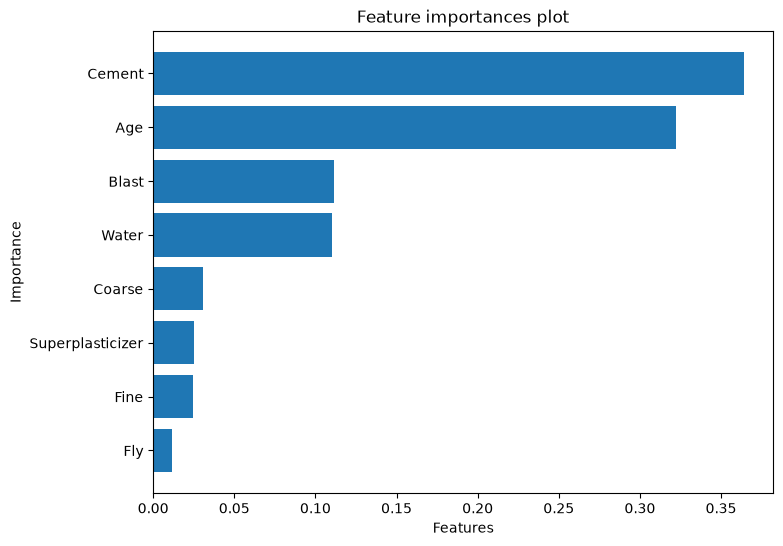

In [61]:
 
bestTree = DecisionTreeRegressor(random_state=26,min_samples_split=2, min_samples_leaf=1,max_depth=None)
 
bestTree.fit(X , y)

df_imp = pd.DataFrame({'features':list(X.columns),
                          'importance': bestTree.feature_importances_})

df_imp.sort_values('importance',inplace=True)
plt.figure(figsize=(8,6))
plt.barh(df_imp['features'], df_imp['importance'])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Feature importances plot')